In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames[:20]:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/296.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/124.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/145.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/112.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/125.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/132.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/169.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/203.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/228.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/294.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/162.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/263.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/131.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/306.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/299.mat
/kaggle/input/datasets/sufian79/cwru-mat-full-dataset/191.mat
/kaggle/

In [2]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/brjapon/cwru-bearing-datasets/feature_time_48k_2048_load_1.csv')
print(df.shape)
print(df.columns.tolist())
print(df.head())
# find the label column — likely 'fault' or 'label' or last column
print(df.iloc[:, -1].value_counts())

(2300, 10)
['max', 'min', 'mean', 'sd', 'rms', 'skewness', 'kurtosis', 'crest', 'form', 'fault']
       max      min      mean        sd       rms  skewness  kurtosis  \
0  0.35986 -0.41890  0.017840  0.122746  0.124006 -0.118571 -0.042219   
1  0.46772 -0.36111  0.022255  0.132488  0.134312  0.174699 -0.081548   
2  0.46855 -0.43809  0.020470  0.149651  0.151008  0.040339 -0.274069   
3  0.58475 -0.54303  0.020960  0.157067  0.158422 -0.023266  0.134692   
4  0.44685 -0.57891  0.022167  0.138189  0.139922 -0.081534  0.402783   

      crest      form       fault  
0  2.901946  6.950855  Ball_007_1  
1  3.482334  6.035202  Ball_007_1  
2  3.102819  7.376926  Ball_007_1  
3  3.691097  7.558387  Ball_007_1  
4  3.193561  6.312085  Ball_007_1  
fault
Ball_007_1    230
Ball_014_1    230
Ball_021_1    230
IR_007_1      230
IR_014_1      230
IR_021_1      230
OR_007_6_1    230
OR_014_6_1    230
OR_021_6_1    230
Normal_1      230
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

X = df.drop(columns=['fault'])
le = LabelEncoder()
y = le.fit_transform(df['fault'])          # XGBoost needs numeric labels

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

clf = XGBClassifier(random_state=42, eval_metric='mlogloss')
clf.fit(Xtr_s, ytr)

pred = clf.predict(Xte_s)
print(classification_report(yte, pred, target_names=le.classes_))

              precision    recall  f1-score   support

  Ball_007_1       0.97      0.85      0.91        46
  Ball_014_1       0.98      0.89      0.93        46
  Ball_021_1       0.84      0.80      0.82        46
    IR_007_1       1.00      1.00      1.00        46
    IR_014_1       1.00      1.00      1.00        46
    IR_021_1       0.94      1.00      0.97        46
    Normal_1       1.00      1.00      1.00        46
  OR_007_6_1       1.00      1.00      1.00        46
  OR_014_6_1       0.76      0.89      0.82        46
  OR_021_6_1       0.98      1.00      0.99        46

    accuracy                           0.94       460
   macro avg       0.95      0.94      0.94       460
weighted avg       0.95      0.94      0.94       460



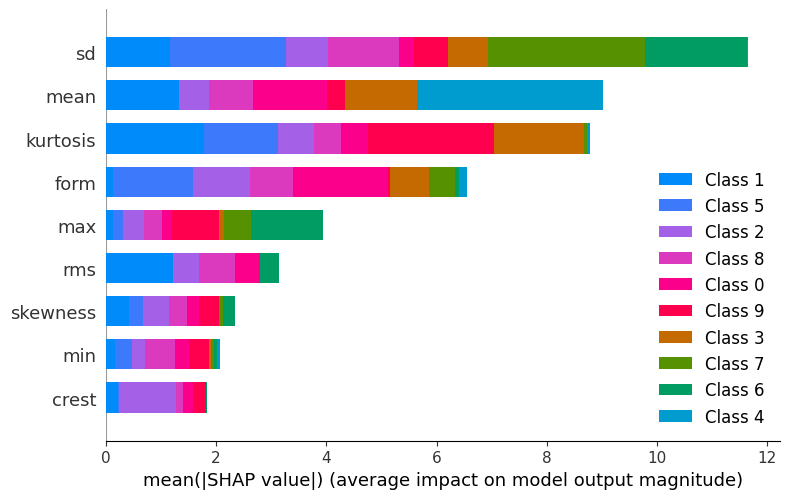

In [4]:
import shap
import matplotlib.pyplot as plt

# SHAP explainer for the tree model
explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(Xte_s)

# Global feature importance across all classes
shap.summary_plot(shap_values, Xte_s, feature_names=X.columns.tolist(),
                  plot_type="bar", show=True)

In [5]:
# Detailed: how each feature pushes predictions (beeswarm), for one class
# shap_values is a list (one array per class); pick a class index
class_idx = list(le.classes_).index('Ball_021_1')   # the hard class
shap.summary_plot(shap_values[class_idx], Xte_s,
                  feature_names=X.columns.tolist(), show=True)

ValueError: The shape of the shap_values matrix does not match the shape of the provided data matrix. Perhaps the extra column in the shap_values matrix is the constant offset? Of so just pass shap_values[:,:-1].

In [6]:
import numpy as np
print(type(shap_values), np.array(shap_values).shape)  # confirm the shape first

<class 'numpy.ndarray'> (460, 9, 10)


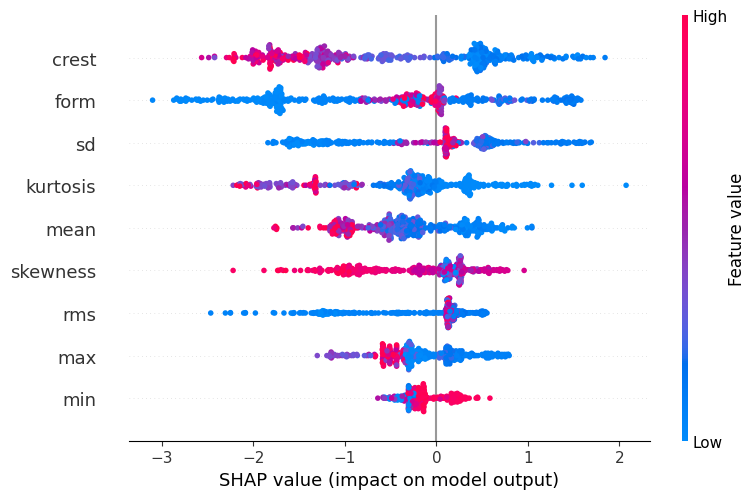

In [7]:
class_idx = list(le.classes_).index('Ball_021_1')
# new SHAP: shape is (samples, features, classes) -> slice last axis
shap.summary_plot(shap_values[:, :, class_idx], Xte_s,
                  feature_names=X.columns.tolist(), show=True)

In [8]:
import matplotlib.pyplot as plt

# Global bar plot, saved at 300 DPI
shap.summary_plot(shap_values, Xte_s, feature_names=X.columns.tolist(),
                  plot_type="bar", show=False)
plt.tight_layout()
plt.savefig('/kaggle/working/shap_global_bar.png', dpi=300, bbox_inches='tight')
plt.close()

# Per-class beeswarm, saved at 300 DPI
shap.summary_plot(shap_values[:, :, class_idx], Xte_s,
                  feature_names=X.columns.tolist(), show=False)
plt.tight_layout()
plt.savefig('/kaggle/working/shap_ball021_beeswarm.png', dpi=300, bbox_inches='tight')
plt.close()

print("saved")

saved


In [10]:
import numpy as np

# Predicted class probabilities
proba = clf.predict_proba(Xte_s)
confidence = proba.max(axis=1)          # how confident on each sample
pred = proba.argmax(axis=1)
correct = (pred == yte)

# Are wrong predictions less confident than correct ones?
print("Mean confidence when CORRECT:", confidence[correct].mean())
print("Mean confidence when WRONG:  ", confidence[~correct].mean())

Mean confidence when CORRECT: 0.9896599
Mean confidence when WRONG:   0.8842634


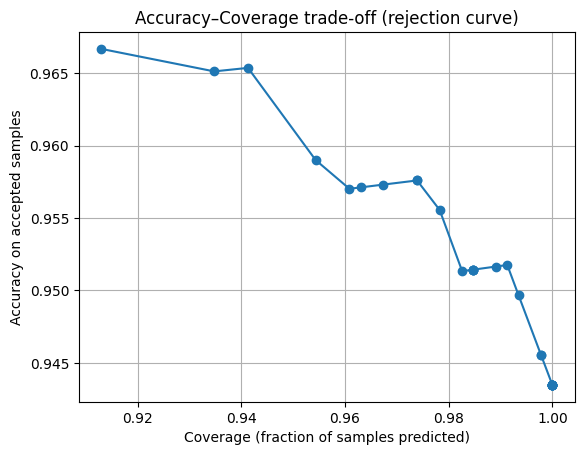

In [11]:
import matplotlib.pyplot as plt

thresholds = np.linspace(0.3, 1.0, 30)
accs, coverage = [], []
for t in thresholds:
    keep = confidence >= t
    if keep.sum() > 0:
        accs.append((pred[keep] == yte[keep]).mean())
        coverage.append(keep.mean())

plt.figure()
plt.plot(coverage, accs, marker='o')
plt.xlabel('Coverage (fraction of samples predicted)')
plt.ylabel('Accuracy on accepted samples')
plt.title('Accuracy–Coverage trade-off (rejection curve)')
plt.grid(True)
plt.savefig('/kaggle/working/rejection_curve.png', dpi=300, bbox_inches='tight')
plt.savefig('/kaggle/working/rejection_curve.pdf', bbox_inches='tight')
plt.show()

In [12]:
import shutil, os
os.makedirs('/kaggle/working/figures', exist_ok=True)
for f in os.listdir('/kaggle/working'):
    if f.endswith(('.png', '.pdf')):
        shutil.copy(f'/kaggle/working/{f}', f'/kaggle/working/figures/{f}')
shutil.make_archive('/kaggle/working/all_figures', 'zip', '/kaggle/working/figures')
print("Created all_figures.zip")

Created all_figures.zip


In [16]:
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("Mean confidence CORRECT: 0.9897\n")
    f.write("Mean confidence WRONG:   0.8843\n")
    f.write("Gap indicates meaningful predictive uncertainty.\n")

In [17]:
import shutil, os

src = '/kaggle/working'
dst = '/kaggle/working/figures'
os.makedirs(dst, exist_ok=True)

count = 0
for f in os.listdir(src):
    full = os.path.join(src, f)
    if os.path.isfile(full) and f.endswith(('.png', '.pdf')):
        shutil.copy(full, os.path.join(dst, f))
        count += 1

print(f"Copied {count} figure files")

if count > 0:
    shutil.make_archive('/kaggle/working/all_figures', 'zip', dst)
    print("Created all_figures.zip")
else:
    print("No .png or .pdf files found in /kaggle/working yet — save some figures first")

Copied 4 figure files
Created all_figures.zip


In [18]:
import os
print(os.listdir('/kaggle/working'))

['rejection_curve.png', 'all_figures.zip', 'shap_global_bar.png', 'results_log.txt', 'figures', 'shap_ball021_beeswarm.png', 'rejection_curve.pdf', '.virtual_documents']


In [19]:
import numpy as np

data = np.load('/kaggle/input/datasets/brjapon/cwru-bearing-datasets/CWRU_48k_load_1_CNN_data.npz')
print(data.files)                    # what arrays are inside
for k in data.files:
    print(k, data[k].shape)

['data', 'labels']
data (4600, 32, 32)
labels (4600,)


In [20]:
import numpy as np
print("labels:", np.unique(data['labels']))   # expect 0-9
print("data range:", data['data'].min(), data['data'].max())

labels: ['Ball_007' 'Ball_014' 'Ball_021' 'IR_007' 'IR_014' 'IR_021' 'Normal'
 'OR_007' 'OR_014' 'OR_021']
data range: -6.2926 6.8259


In [21]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

X = data['data'].astype('float32')
y = data['labels'].astype('int')

# normalize to roughly [0,1] or standardize
X = (X - X.mean()) / (X.std() + 1e-8)
X = X[..., np.newaxis]          # add channel dim -> (4600, 32, 32, 1)

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

model = models.Sequential([
    layers.Input((32, 32, 1)),
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu', padding='same'),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),                 # dropout also enables MC-dropout uncertainty later
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax'),
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

history = model.fit(Xtr, ytr, validation_split=0.2,
                    epochs=30, batch_size=64, verbose=1)

ValueError: invalid literal for int() with base 10: np.str_('Ball_007')

In [22]:
import numpy as np
from sklearn.preprocessing import LabelEncoder

X = data['data'].astype('float32')

le_cnn = LabelEncoder()
y = le_cnn.fit_transform(data['labels'])   # strings -> 0..9
print("classes:", le_cnn.classes_)         # note the order for later
print("num classes:", len(le_cnn.classes_))

classes: ['Ball_007' 'Ball_014' 'Ball_021' 'IR_007' 'IR_014' 'IR_021' 'Normal'
 'OR_007' 'OR_014' 'OR_021']
num classes: 10


I0000 00:00:1783273578.765630      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1783273578.768592      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,578 (396.79 KB)

 Trainable params: 101,578 (396.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
42/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1339 - loss: 2.1299

I0000 00:00:1783273585.540110     180 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - accuracy: 0.2092 - loss: 1.9705 - val_accuracy: 0.3995 - val_loss: 1.6098
Epoch 2/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5163 - loss: 1.3546 - val_accuracy: 0.6807 - val_loss: 0.9400
Epoch 3/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7266 - loss: 0.7432 - val_accuracy: 0.8750 - val_loss: 0.4133
Epoch 4/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8071 - loss: 0.4992 - val_accuracy: 0.8288 - val_loss: 0.3892
Epoch 5/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8356 - loss: 0.4139 - val_accuracy: 0.8940 - val_loss: 0.3011
Epoch 6/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8529 - loss: 0.3649 - val_accuracy: 0.8832 - val_loss: 0.2771
Epoch 7/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8546 - loss: 0.3413 - val_accuracy: 0.9022 - val_loss: 0.2373
Epoch 8/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8862 - loss: 0.2809 - val_accuracy: 0.9130 - val_loss: 0.2115
Ep

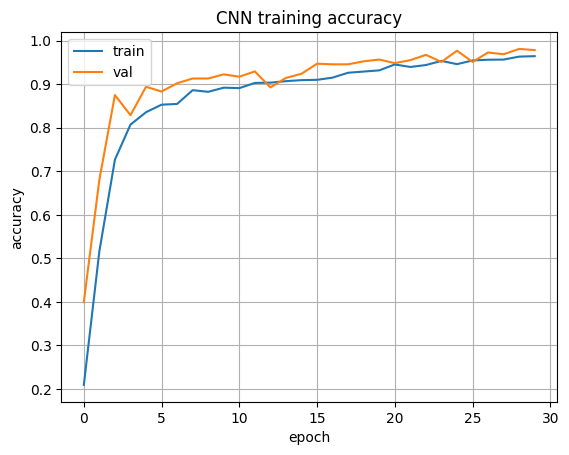

In [23]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# --- Load and prep ---
data = np.load('/kaggle/input/datasets/brjapon/cwru-bearing-datasets/CWRU_48k_load_1_CNN_data.npz')

X = data['data'].astype('float32')
le_cnn = LabelEncoder()
y = le_cnn.fit_transform(data['labels'])        # strings -> 0..9

X = (X - X.mean()) / (X.std() + 1e-8)           # standardize
X = X[..., np.newaxis]                           # (4600, 32, 32, 1)

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# --- Model ---
model = models.Sequential([
    layers.Input((32, 32, 1)),
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu', padding='same'),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),                          # enables MC-dropout later
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax'),
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

# --- Train ---
history = model.fit(Xtr, ytr, validation_split=0.2,
                    epochs=30, batch_size=64, verbose=1)

# --- Evaluate ---
pred = model.predict(Xte).argmax(axis=1)
print(classification_report(yte, pred, target_names=le_cnn.classes_))

# --- Save training curve ---
plt.figure()
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.grid(True)
plt.title('CNN training accuracy')
plt.savefig('/kaggle/working/cnn_training_curve.png', dpi=300, bbox_inches='tight')
plt.savefig('/kaggle/working/cnn_training_curve.pdf', bbox_inches='tight')
plt.show()

In [24]:
import shutil, os
dst = '/kaggle/working/figures'
os.makedirs(dst, exist_ok=True)
for f in os.listdir('/kaggle/working'):
    if f.endswith(('.png', '.pdf')):
        shutil.copy(f'/kaggle/working/{f}', f'{dst}/{f}')
shutil.make_archive('/kaggle/working/all_figures', 'zip', dst)
print("re-zipped all figures")

re-zipped all figures


In [25]:
import numpy as np

# Enable dropout at inference by calling model with training=True, many times
T = 50
preds = np.stack([model(Xte, training=True).numpy() for _ in range(T)])  # (T, N, 10)
mean_pred = preds.mean(axis=0)
pred_class = mean_pred.argmax(axis=1)
uncertainty = preds.std(axis=0).mean(axis=1)   # spread across passes = uncertainty

correct = (pred_class == yte)
print("Mean uncertainty when CORRECT:", uncertainty[correct].mean())
print("Mean uncertainty when WRONG:  ", uncertainty[~correct].mean())

Mean uncertainty when CORRECT: 0.0072717858
Mean uncertainty when WRONG:   0.03897543


In [26]:
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("\nCNN accuracy: 0.97\n")
    f.write("CNN MC-dropout uncertainty CORRECT: 0.0073\n")
    f.write("CNN MC-dropout uncertainty WRONG:   0.0390 (5x higher)\n")

In [27]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

# reload fresh so this cell is self-contained
df = pd.read_csv('/kaggle/input/datasets/brjapon/cwru-bearing-datasets/feature_time_48k_2048_load_1.csv')

Xall = df.drop(columns=['fault'])
yall = LabelEncoder().fit_transform(df['fault'])

results = []
for feats, name in [(Xall.columns.tolist(), 'All 9 features'),
                    (['sd', 'mean', 'kurtosis', 'form'], 'Top-4 SHAP features'),
                    (['max', 'min'], 'Weak features only')]:
    Xs = Xall[feats]
    Xtr, Xte, ytr, yte = train_test_split(Xs, yall, test_size=0.2,
                                          stratify=yall, random_state=42)
    sc = StandardScaler().fit(Xtr)
    clf = XGBClassifier(random_state=42, eval_metric='mlogloss')
    clf.fit(sc.transform(Xtr), ytr)
    acc = accuracy_score(yte, clf.predict(sc.transform(Xte)))
    results.append((name, acc))
    print(f"{name}: {acc:.3f}")

All 9 features: 0.943
Top-4 SHAP features: 0.946
Weak features only: 0.663


In [28]:
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("\nABLATION (XGBoost):\n")
    f.write("All 9 features:      0.943\n")
    f.write("Top-4 SHAP features: 0.946\n")
    f.write("Weak features only:  0.663\n")

In [29]:
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("\nABLATION (XGBoost):\n")
    f.write("All 9 features:      0.943\n")
    f.write("Top-4 SHAP features: 0.946\n")
    f.write("Weak features only:  0.663\n")
print("logged")

logged


In [30]:
import os

pb_root = '/kaggle/input/datasets/dippatel/paderborn-db'  # adjust if the path differs
count = 0
for dirname, _, filenames in os.walk('/kaggle/input'):
    if 'paderborn' in dirname.lower() or 'paderborn' in ''.join(filenames).lower():
        for f in filenames[:15]:
            print(os.path.join(dirname, f))
            count += 1
    if count > 40:
        break

/kaggle/input/datasets/dippatel03/paderborn-db/K004/N15_M01_F10_K004_16.mat
/kaggle/input/datasets/dippatel03/paderborn-db/K004/N15_M07_F04_K004_8.mat
/kaggle/input/datasets/dippatel03/paderborn-db/K004/N15_M07_F10_K004_2.mat
/kaggle/input/datasets/dippatel03/paderborn-db/K004/N09_M07_F10_K004_2.mat
/kaggle/input/datasets/dippatel03/paderborn-db/K004/N09_M07_F10_K004_7.mat
/kaggle/input/datasets/dippatel03/paderborn-db/K004/N15_M01_F10_K004_8.mat
/kaggle/input/datasets/dippatel03/paderborn-db/K004/N15_M07_F10_K004_12.mat
/kaggle/input/datasets/dippatel03/paderborn-db/K004/N15_M01_F10_K004_20.mat
/kaggle/input/datasets/dippatel03/paderborn-db/K004/N15_M01_F10_K004_1.mat
/kaggle/input/datasets/dippatel03/paderborn-db/K004/N09_M07_F10_K004_3.mat
/kaggle/input/datasets/dippatel03/paderborn-db/K004/N09_M07_F10_K004_8.mat
/kaggle/input/datasets/dippatel03/paderborn-db/K004/K004.pdf
/kaggle/input/datasets/dippatel03/paderborn-db/K004/N15_M07_F04_K004_9.mat
/kaggle/input/datasets/dippatel03/pa

In [31]:
import scipy.io as sio
import numpy as np

f = '/kaggle/input/datasets/dippatel03/paderborn-db/K004/N15_M07_F10_K004_2.mat'
mat = sio.loadmat(f)
print("top keys:", [k for k in mat.keys() if not k.startswith('__')])

# Paderborn nests everything under a struct named like the file. Explore it:
key = [k for k in mat.keys() if not k.startswith('__')][0]
print("struct dtype names:", mat[key].dtype.names if mat[key].dtype.names else "flat array")

top keys: ['N15_M07_F10_K004_2']
struct dtype names: ('Info', 'X', 'Y', 'Description')


In [32]:
import scipy.io as sio
import numpy as np

f = '/kaggle/input/datasets/dippatel03/paderborn-db/K004/N15_M07_F10_K004_2.mat'
mat = sio.loadmat(f)
key = 'N15_M07_F10_K004_2'
struct = mat[key][0, 0]

Y = struct['Y']            # the signal container
print("Y shape:", Y.shape)
print("Y[0,0] field names:", Y[0, 0].dtype.names if Y[0,0].dtype.names else "none")

# Paderborn Y is a list of channels; each has a 'Name' and 'Data'
for i in range(Y.shape[1]):
    name = Y[0, i]['Name'][0] if 'Name' in Y[0,i].dtype.names else '?'
    data = Y[0, i]['Data']
    print(i, "->", name, "| data shape:", np.array(data).shape)

Y shape: (1, 7)
Y[0,0] field names: ('Name', 'Type', 'Data', 'Unit', 'Raster', 'Device', 'XIndex', 'DownSampling', 'Description', 'DisplayIdentifier', 'Path', 'Flags', 'Min', 'Max', 'MinWeak', 'MaxWeak')
0 -> force | data shape: (1, 16001)
1 -> phase_current_1 | data shape: (1, 256001)
2 -> phase_current_2 | data shape: (1, 256001)
3 -> speed | data shape: (1, 16001)
4 -> temp_2_bearing_module | data shape: (1, 5)
5 -> torque | data shape: (1, 16001)
6 -> vibration_1 | data shape: (1, 256001)


In [33]:
import os
root = '/kaggle/input/datasets/dippatel03/paderborn-db'
print(sorted([d for d in os.listdir(root) if os.path.isdir(f'{root}/{d}')]))

['K001', 'K002', 'K003', 'K004', 'K005', 'K006', 'KA01', 'KA03', 'KA04', 'KA05', 'KA06', 'KA07', 'KA08', 'KA09', 'KA15', 'KA16', 'KA22', 'KA30', 'KB23', 'KB24', 'KB27', 'KI01', 'KI03', 'KI04', 'KI05', 'KI07', 'KI08', 'KI14', 'KI16', 'KI17', 'KI18', 'KI21']


In [34]:
import scipy.io as sio
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
import os, glob

ROOT = '/kaggle/input/datasets/dippatel03/paderborn-db'
COND = 'N15_M07_F10'          # fixed operating condition
WIN  = 2048                   # same window as CWRU features

# Balanced bearing selection: 2 codes per class
SELECTION = {
    'Normal': ['K001', 'K002'],
    'OR':     ['KA04', 'KA07'],   # real (fatigue) outer-race damage
    'IR':     ['KI04', 'KI07'],   # real inner-race damage
}

def extract_features(sig):
    """Same 9 time-domain features as the CWRU CSV."""
    mx, mn = sig.max(), sig.min()
    mean = sig.mean()
    sd = sig.std()
    rms = np.sqrt(np.mean(sig**2))
    sk = skew(sig)
    kt = kurtosis(sig)                       # Fisher (excess) kurtosis
    crest = mx / (rms + 1e-12)
    form = rms / (abs(mean) + 1e-12)
    return [mx, mn, mean, sd, rms, sk, kt, crest, form]

COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']

rows, labels = [], []
for label, codes in SELECTION.items():
    for code in codes:
        files = glob.glob(f'{ROOT}/{code}/{COND}_{code}_*.mat')
        for f in files:
            key = os.path.splitext(os.path.basename(f))[0]
            try:
                mat = sio.loadmat(f)
                sig = np.array(mat[key][0,0]['Y'][0,6]['Data']).squeeze()  # vibration_1
            except Exception as e:
                continue
            # segment into non-overlapping windows
            n = len(sig) // WIN
            for i in range(n):
                seg = sig[i*WIN:(i+1)*WIN]
                rows.append(extract_features(seg))
                labels.append(label)

pb = pd.DataFrame(rows, columns=COLS)
pb['fault'] = labels
print(pb.shape)
print(pb['fault'].value_counts())
pb.head()

(15029, 10)
fault
OR        5012
Normal    5010
IR        5007
Name: count, dtype: int64


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,fault
0,3.302002,-2.801514,-0.005153,0.451275,0.451305,0.227332,9.983256,7.316569,87.584000,Normal
1,2.450562,-1.950073,-0.010055,0.366652,0.366789,0.667674,8.865745,6.681113,36.477207,Normal
2,2.490234,-2.413940,-0.013061,0.412560,0.412766,0.022669,8.115710,6.033034,31.603298,Normal
3,2.563477,-2.850342,-0.017987,0.425267,0.425647,0.072683,7.729939,6.022543,23.663888,Normal
4,3.247070,-2.871704,-0.024813,0.395158,0.395937,0.011370,9.680529,8.200982,15.956562,Normal


In [35]:
import pandas as pd
import matplotlib.pyplot as plt

# reload CWRU 3-class subset to match Paderborn's label space
cwru = pd.read_csv('/kaggle/input/datasets/brjapon/cwru-bearing-datasets/feature_time_48k_2048_load_1.csv')

# map CWRU's fine labels to 3 classes; drop Ball
def to3(x):
    if x.startswith('IR'): return 'IR'
    if x.startswith('OR'): return 'OR'
    if x.startswith('Normal'): return 'Normal'
    return None
cwru['fault3'] = cwru['fault'].map(to3)
cwru3 = cwru[cwru['fault3'].notna()].copy()
print("CWRU 3-class counts:\n", cwru3['fault3'].value_counts())

# compare per-feature means, Normal class only
feats = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']
print("\nFeature means — CWRU Normal vs Paderborn Normal:")
comp = pd.DataFrame({
    'CWRU':   cwru3[cwru3['fault3']=='Normal'][feats].mean(),
    'Paderborn': pb[pb['fault']=='Normal'][feats].mean()
})
print(comp)

CWRU 3-class counts:
 fault3
IR        690
OR        690
Normal    230
Name: count, dtype: int64

Feature means — CWRU Normal vs Paderborn Normal:
              CWRU  Paderborn
max       0.205093   2.237693
min      -0.206493  -2.249114
mean      0.012488  -0.013620
sd        0.065046   0.314698
rms       0.066265   0.315049
skewness -0.173084   0.026123
kurtosis -0.095627  10.159280
crest     3.093996   7.200859
form      5.529295  51.687523


In [36]:
import scipy.io as sio, numpy as np, pandas as pd, glob, os, re
from scipy.stats import skew, kurtosis

RAW = '/kaggle/input/datasets/brjapon/cwru-bearing-datasets/raw'
WIN = 2048

def extract_features(sig):
    mx, mn = sig.max(), sig.min()
    mean = sig.mean(); sd = sig.std()
    rms = np.sqrt(np.mean(sig**2))
    return [mx, mn, mean, sd, rms, skew(sig), kurtosis(sig),
            mx/(rms+1e-12), rms/(abs(mean)+1e-12)]

COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']

def label3(fname):
    b = os.path.basename(fname)
    if b.startswith('IR'): return 'IR'
    if b.startswith('OR'): return 'OR'
    if b.startswith('Time_Normal') or b.startswith('Normal'): return 'Normal'
    return None   # skip Ball

rows, labels = [], []
for f in glob.glob(f'{RAW}/*.mat'):
    lab = label3(f)
    if lab is None:
        continue
    mat = sio.loadmat(f)
    # CWRU signal key ends in _DE_time (drive-end accelerometer)
    de_keys = [k for k in mat if k.endswith('DE_time')]
    if not de_keys:
        continue
    sig = mat[de_keys[0]].squeeze()
    n = len(sig) // WIN
    for i in range(n):
        rows.append(extract_features(sig[i*WIN:(i+1)*WIN]))
        labels.append(lab)

cwru_re = pd.DataFrame(rows, columns=COLS)
cwru_re['fault'] = labels
print(cwru_re.shape)
print(cwru_re['fault'].value_counts())

# now compare Normal means again — same pipeline both sides
comp = pd.DataFrame({
    'CWRU_re': cwru_re[cwru_re['fault']=='Normal'][COLS].mean(),
    'Paderborn': pb[pb['fault']=='Normal'][COLS].mean()
})
print(comp)

(1658, 10)
fault
IR        711
OR        711
Normal    236
Name: count, dtype: int64
           CWRU_re  Paderborn
max       0.205447   2.237693
min      -0.207013  -2.249114
mean      0.012560  -0.013620
sd        0.065060   0.314698
rms       0.066310   0.315049
skewness -0.173723   0.026123
kurtosis -0.090634  10.159280
crest     3.096754   7.200859
form      5.502521  51.687523


In [37]:
import numpy as np, pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']

le = LabelEncoder().fit(['IR','Normal','OR'])
Xc, yc = cwru_re[COLS].values, le.transform(cwru_re['fault'])
Xp, yp = pb[COLS].values,      le.transform(pb['fault'])

# --- Experiment 1: cold transfer, RAW features ---
clf = XGBClassifier(random_state=42, eval_metric='mlogloss')
clf.fit(Xc, yc)
acc_raw = accuracy_score(yp, clf.predict(Xp))
print("COLD TRANSFER (raw features): %.3f" % acc_raw)
print(confusion_matrix(yp, clf.predict(Xp)))

COLD TRANSFER (raw features): 0.325
[[2247    0 2760]
 [   0    0 5010]
 [2381    0 2631]]


In [38]:
# --- Experiment 2: cold transfer, per-dataset standardized ---
sc_c = StandardScaler().fit(Xc)
sc_p = StandardScaler().fit(Xp)
clf2 = XGBClassifier(random_state=42, eval_metric='mlogloss')
clf2.fit(sc_c.transform(Xc), yc)
acc_std = accuracy_score(yp, clf2.predict(sc_p.transform(Xp)))
print("COLD TRANSFER (per-dataset standardized): %.3f" % acc_std)
print(confusion_matrix(yp, clf2.predict(sc_p.transform(Xp))))

SyntaxError: incomplete input (1843850676.py, line 8)

In [39]:
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

sc_c = StandardScaler().fit(Xc)
sc_p = StandardScaler().fit(Xp)
clf2 = XGBClassifier(random_state=42, eval_metric='mlogloss')
clf2.fit(sc_c.transform(Xc), yc)
pred2 = clf2.predict(sc_p.transform(Xp))
acc_std = accuracy_score(yp, pred2)
print("COLD TRANSFER (per-dataset standardized): %.3f" % acc_std)
print(confusion_matrix(yp, pred2))

COLD TRANSFER (per-dataset standardized): 0.337
[[2460  235 2312]
 [ 124  469 4417]
 [1696 1174 2142]]


In [41]:
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("\nCROSS-TRANSFER CWRU->Paderborn:\n")
    f.write("Raw features: 0.325 (Normal class fully collapses to OR)\n")

In [42]:
with open('/kaggle/working/results_log.txt', 'a') as f:
    f.write("Per-dataset standardized: 0.337 (no improvement - gap is structural)\n")

In [43]:
import numpy as np
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from scipy.linalg import sqrtm

COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']
le = LabelEncoder().fit(['IR','Normal','OR'])
Xc, yc = cwru_re[COLS].values.astype(float), le.transform(cwru_re['fault'])
Xp, yp = pb[COLS].values.astype(float),      le.transform(pb['fault'])

def coral(Xs, Xt):
    """Align source features Xs to target Xt via covariance whitening+recoloring."""
    Xs = (Xs - Xs.mean(0)) / (Xs.std(0) + 1e-8)
    Xt = (Xt - Xt.mean(0)) / (Xt.std(0) + 1e-8)
    Cs = np.cov(Xs, rowvar=False) + np.eye(Xs.shape[1])
    Ct = np.cov(Xt, rowvar=False) + np.eye(Xt.shape[1])
    Xs_white = Xs @ np.real(sqrtm(np.linalg.inv(Cs)))     # whiten source
    Xs_align = Xs_white @ np.real(sqrtm(Ct))              # recolor to target
    Xt_std = Xt
    return Xs_align, Xt_std

Xc_aligned, Xp_std = coral(Xc, Xp)

clf = XGBClassifier(random_state=42, eval_metric='mlogloss')
clf.fit(Xc_aligned, yc)
pred = clf.predict(Xp_std)
acc_coral = accuracy_score(yp, pred)
print("COLD TRANSFER (CORAL domain adaptation): %.3f" % acc_coral)
print(confusion_matrix(yp, pred))

COLD TRANSFER (CORAL domain adaptation): 0.363
[[2909   33 2065]
 [ 142   99 4769]
 [1983  577 2452]]


In [44]:
import scipy.io as sio, numpy as np, glob, os
from scipy.stats import zscore

WIN = 2048   # window length (samples)

# ---------- CWRU raw windows (3-class, from raw/ .mat) ----------
RAW = '/kaggle/input/datasets/brjapon/cwru-bearing-datasets/raw'
def cwru_label(f):
    b = os.path.basename(f)
    if b.startswith('IR'): return 'IR'
    if b.startswith('OR'): return 'OR'
    if b.startswith('Time_Normal') or b.startswith('Normal'): return 'Normal'
    return None

Xc_raw, yc_raw = [], []
for f in glob.glob(f'{RAW}/*.mat'):
    lab = cwru_label(f)
    if lab is None: continue
    mat = sio.loadmat(f)
    de = [k for k in mat if k.endswith('DE_time')]
    if not de: continue
    sig = mat[de[0]].squeeze().astype(float)
    for i in range(len(sig)//WIN):
        seg = sig[i*WIN:(i+1)*WIN]
        Xc_raw.append((seg - seg.mean())/(seg.std()+1e-8))  # per-window z-norm
        yc_raw.append(lab)

# ---------- Paderborn raw windows (3-class, one condition) ----------
ROOT = '/kaggle/input/datasets/dippatel03/paderborn-db'
COND = 'N15_M07_F10'
SEL = {'Normal':['K001','K002'], 'OR':['KA04','KA07'], 'IR':['KI04','KI07']}

Xp_raw, yp_raw = [], []
for lab, codes in SEL.items():
    for code in codes:
        for f in glob.glob(f'{ROOT}/{code}/{COND}_{code}_*.mat'):
            key = os.path.splitext(os.path.basename(f))[0]
            try:
                mat = sio.loadmat(f)
                sig = np.array(mat[key][0,0]['Y'][0,6]['Data']).squeeze().astype(float)
            except Exception:
                continue
            for i in range(len(sig)//WIN):
                seg = sig[i*WIN:(i+1)*WIN]
                Xp_raw.append((seg - seg.mean())/(seg.std()+1e-8))
                yp_raw.append(lab)

Xc_raw = np.array(Xc_raw); Xp_raw = np.array(Xp_raw)
print("CWRU raw:", Xc_raw.shape, "| Paderborn raw:", Xp_raw.shape)
import collections
print("CWRU:", collections.Counter(yc_raw))
print("PB:  ", collections.Counter(yp_raw))

CWRU raw: (1658, 2048) | Paderborn raw: (15029, 2048)
CWRU: Counter({'IR': 711, 'OR': 711, 'Normal': 236})
PB:   Counter({'OR': 5012, 'Normal': 5010, 'IR': 5007})


In [45]:
import numpy as np
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder().fit(['IR','Normal','OR'])
yc = le.transform(yc_raw)
yp = le.transform(yp_raw)

# --- subsample Paderborn to ~match CWRU size, keep classes balanced ---
rng = np.random.default_rng(42)
target_per_class = 700   # close to CWRU's IR/OR count
idx_keep = []
for c in range(3):
    ci = np.where(yp == c)[0]
    idx_keep.extend(rng.choice(ci, size=min(target_per_class, len(ci)), replace=False))
idx_keep = np.array(idx_keep); rng.shuffle(idx_keep)

Xp_bal = Xp_raw[idx_keep]
yp_bal = yp[idx_keep]

print("CWRU:", Xc_raw.shape[0], "| Paderborn balanced:", Xp_bal.shape[0])
import collections
print("PB balanced classes:", collections.Counter(le.inverse_transform(yp_bal)))

# reshape for 1D-CNN: (N, 2048, 1)
Xc = Xc_raw[..., None].astype('float32')
Xp = Xp_bal[..., None].astype('float32')

# class weights for CWRU label classifier (Normal is scarce)
from sklearn.utils.class_weight import compute_class_weight
cw = compute_class_weight('balanced', classes=np.arange(3), y=yc)
class_weight = {i: w for i, w in enumerate(cw)}
print("class weights:", class_weight)

CWRU: 1658 | Paderborn balanced: 2100
PB balanced classes: Counter({np.str_('OR'): 700, np.str_('Normal'): 700, np.str_('IR'): 700})
class weights: {0: np.float64(0.7773089545241444), 1: np.float64(2.34180790960452), 2: np.float64(0.7773089545241444)}


In [46]:
import tensorflow as tf
from tensorflow.keras import layers, Model
import numpy as np

# ---- Gradient Reversal Layer ----
@tf.custom_gradient
def grad_reverse(x, lamb):
    y = tf.identity(x)
    def grad(dy):
        return -lamb * dy, None
    return y, grad

class GRL(layers.Layer):
    def __init__(self, **kw): super().__init__(**kw); self.lamb = tf.Variable(1.0, trainable=False)
    def call(self, x): return grad_reverse(x, self.lamb)

# ---- Shared feature extractor ----
def build_dann():
    inp = layers.Input((2048, 1))
    x = layers.Conv1D(32, 16, strides=2, activation='relu', padding='same')(inp)
    x = layers.MaxPool1D(2)(x)
    x = layers.Conv1D(64, 8, strides=2, activation='relu', padding='same')(x)
    x = layers.MaxPool1D(2)(x)
    x = layers.Conv1D(128, 4, activation='relu', padding='same')(x)
    x = layers.GlobalAveragePooling1D()(x)
    feat = layers.Dense(128, activation='relu', name='features')(x)

    # label head (3 classes)
    lp = layers.Dropout(0.3)(feat)
    label_out = layers.Dense(3, activation='softmax', name='label')(lp)

    # domain head (2 domains) via gradient reversal
    grl = GRL()(feat)
    dp = layers.Dense(64, activation='relu')(grl)
    domain_out = layers.Dense(2, activation='softmax', name='domain')(dp)

    return Model(inp, [label_out, domain_out]), Model(inp, label_out)

dann, label_model = build_dann()
dann.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss={'label':'sparse_categorical_crossentropy',
          'domain':'sparse_categorical_crossentropy'},
    loss_weights={'label':1.0, 'domain':1.0},
    metrics={'label':'accuracy'})
dann.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 2048, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 1024, 32)  │        544 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 512, 32)   │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 256, 64)   │     16,448 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 128, 64)   │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 128, 128)  │     32,896 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ conv1d_2[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ features (Dense)    │ (None, 128)       │     16,512 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ grl (GRL)           │ (None, 128)       │          0 │ features[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ features[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ grl[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ label (Dense)       │ (None, 3)         │        387 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ domain (Dense)      │ (None, 2)         │        130 │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 75,173 (293.64 KB)

 Trainable params: 75,173 (293.64 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
import numpy as np
import tensorflow as tf

# domain labels: CWRU=0, Paderborn=1
Xc_t = tf.constant(Xc); yc_t = tf.constant(yc, dtype=tf.int32)
Xp_t = tf.constant(Xp); yp_t = tf.constant(yp_bal, dtype=tf.int32)

n_c, n_p = len(Xc), len(Xp)
BATCH = 64
EPOCHS = 60
steps = max(n_c, n_p) // BATCH

opt = tf.keras.optimizers.Adam(1e-3)
cce = tf.keras.losses.SparseCategoricalCrossentropy()
cw_vec = tf.constant([class_weight[0], class_weight[1], class_weight[2]], dtype=tf.float32)

def sample(X, y, k):
    idx = np.random.randint(0, len(X), k)
    return tf.gather(X, idx), tf.gather(y, idx)

@tf.function
def train_step(xc, yc_b, xp_b, lamb):
    dann.get_layer(index=[i for i,l in enumerate(dann.layers) if l.name=='grl' or isinstance(l,GRL)][0]).lamb.assign(lamb) if False else None
    with tf.GradientTape() as tape:
        # label loss on CWRU (weighted)
        lbl_pred, dom_pred_c = dann(xc, training=True)
        w = tf.gather(cw_vec, yc_b)
        label_loss = tf.reduce_mean(w * tf.keras.losses.sparse_categorical_crossentropy(yc_b, lbl_pred))
        # domain loss on both (CWRU=0, PB=1)
        _, dom_pred_p = dann(xp_b, training=True)
        dom_c = tf.zeros(tf.shape(xc)[0], dtype=tf.int32)
        dom_p = tf.ones(tf.shape(xp_b)[0], dtype=tf.int32)
        domain_loss = (cce(dom_c, dom_pred_c) + cce(dom_p, dom_pred_p)) / 2.0
        total = label_loss + domain_loss
    grads = tape.gradient(total, dann.trainable_variables)
    opt.apply_gradients(zip(grads, dann.trainable_variables))
    return label_loss, domain_loss

# find the GRL layer to set lambda each epoch
grl_layer = [l for l in dann.layers if isinstance(l, GRL)][0]

from sklearn.metrics import accuracy_score
for ep in range(EPOCHS):
    p = ep / EPOCHS
    lamb = 2.0/(1.0+np.exp(-10*p)) - 1.0          # ramp 0->1 (standard DANN schedule)
    grl_layer.lamb.assign(float(lamb))
    ll = dl = 0.0
    for _ in range(steps):
        xc_b, yc_b = sample(Xc_t, yc_t, BATCH)
        xp_b, _    = sample(Xp_t, yp_t, BATCH)
        a, b = train_step(xc_b, yc_b, xp_b, float(lamb))
        ll += float(a); dl += float(b)
    if ep % 5 == 0 or ep == EPOCHS-1:
        pb_pred = label_model.predict(Xp, verbose=0).argmax(1)
        acc = accuracy_score(yp_bal, pb_pred)
        print(f"ep {ep:2d} | lambda {lamb:.2f} | label {ll/steps:.3f} | domain {dl/steps:.3f} | PB acc {acc:.3f}")

ep  0 | lambda 0.00 | label 0.600 | domain 0.571 | PB acc 0.538
ep  5 | lambda 0.39 | label 0.107 | domain 1.822 | PB acc 0.333
ep 10 | lambda 0.68 | label 0.028 | domain 0.501 | PB acc 0.333
ep 15 | lambda 0.85 | label 0.450 | domain 1.733 | PB acc 0.333
ep 20 | lambda 0.93 | label 0.705 | domain 0.248 | PB acc 0.397
ep 25 | lambda 0.97 | label 0.000 | domain 0.001 | PB acc 0.414
ep 30 | lambda 0.99 | label 0.000 | domain 0.001 | PB acc 0.430
ep 35 | lambda 0.99 | label 0.000 | domain 0.001 | PB acc 0.450
ep 40 | lambda 1.00 | label 0.000 | domain 0.003 | PB acc 0.400
ep 45 | lambda 1.00 | label 0.000 | domain 0.002 | PB acc 0.390
ep 50 | lambda 1.00 | label 0.001 | domain 0.001 | PB acc 0.341
ep 55 | lambda 1.00 | label 0.000 | domain 0.001 | PB acc 0.345
ep 59 | lambda 1.00 | label 0.023 | domain 0.033 | PB acc 0.491


In [48]:
opt = tf.keras.optimizers.Adam(3e-4)          # lower LR
grl_layer = [l for l in dann.layers if isinstance(l, GRL)][0]

from sklearn.metrics import accuracy_score
LAMBDA_MAX = 0.3                               # much softer adversary
EPOCHS = 80

for ep in range(EPOCHS):
    p = ep / EPOCHS
    lamb = LAMBDA_MAX * (2.0/(1.0+np.exp(-5*p)) - 1.0)   # slow ramp, low ceiling
    grl_layer.lamb.assign(float(lamb))
    ll = dl = 0.0
    for _ in range(steps):
        xc_b, yc_b = sample(Xc_t, yc_t, BATCH)
        xp_b, _    = sample(Xp_t, yp_t, BATCH)
        a, b = train_step(xc_b, yc_b, xp_b, float(lamb))
        ll += float(a); dl += float(b)
    if ep % 5 == 0 or ep == EPOCHS-1:
        pb_pred = label_model.predict(Xp, verbose=0).argmax(1)
        acc = accuracy_score(yp_bal, pb_pred)
        print(f"ep {ep:2d} | lambda {lamb:.3f} | label {ll/steps:.3f} | domain {dl/steps:.3f} | PB acc {acc:.3f}")

ep  0 | lambda 0.000 | label 0.070 | domain 0.046 | PB acc 0.354


ValueError: in user code:

    File "/tmp/ipykernel_58/1580509300.py", line 36, in train_step  *
        opt.apply_gradients(zip(grads, dann.trainable_variables))
    File "/usr/local/lib/python3.12/dist-packages/keras/src/optimizers/base_optimizer.py", line 462, in apply_gradients  **
        self.apply(grads, trainable_variables)
    File "/usr/local/lib/python3.12/dist-packages/keras/src/optimizers/base_optimizer.py", line 501, in apply
        self.build(trainable_variables)
    File "/usr/local/lib/python3.12/dist-packages/keras/src/optimizers/adam.py", line 93, in build
        self._momentums, self._velocities = self.add_optimizer_variables(
    File "/usr/local/lib/python3.12/dist-packages/keras/src/optimizers/base_optimizer.py", line 389, in add_optimizer_variables
        self.add_variable_from_reference(
    File "/usr/local/lib/python3.12/dist-packages/keras/src/backend/tensorflow/optimizer.py", line 35, in add_variable_from_reference
        return super().add_variable_fro

In [49]:
import tensorflow as tf, numpy as np
from sklearn.metrics import accuracy_score

# 1) rebuild model fresh (resets weights)
dann, label_model = build_dann()
grl_layer = [l for l in dann.layers if isinstance(l, GRL)][0]

# 2) new optimizer
opt = tf.keras.optimizers.Adam(3e-4)
cw_vec = tf.constant([class_weight[0], class_weight[1], class_weight[2]], dtype=tf.float32)

# 3) redefine train_step AFTER optimizer exists (fresh trace)
@tf.function
def train_step(xc, yc_b, xp_b):
    with tf.GradientTape() as tape:
        lbl_pred, dom_pred_c = dann(xc, training=True)
        w = tf.gather(cw_vec, yc_b)
        label_loss = tf.reduce_mean(
            w * tf.keras.losses.sparse_categorical_crossentropy(yc_b, lbl_pred))
        _, dom_pred_p = dann(xp_b, training=True)
        dom_c = tf.zeros(tf.shape(xc)[0], dtype=tf.int32)
        dom_p = tf.ones(tf.shape(xp_b)[0], dtype=tf.int32)
        domain_loss = (
            tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(dom_c, dom_pred_c)) +
            tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(dom_p, dom_pred_p))
        ) / 2.0
        total = label_loss + domain_loss
    grads = tape.gradient(total, dann.trainable_variables)
    opt.apply_gradients(zip(grads, dann.trainable_variables))
    return label_loss, domain_loss

# 4) data tensors
Xc_t = tf.constant(Xc); yc_t = tf.constant(yc, dtype=tf.int32)
Xp_t = tf.constant(Xp); yp_t = tf.constant(yp_bal, dtype=tf.int32)
def sample(X, y, k):
    idx = np.random.randint(0, len(X), k)
    return tf.gather(X, idx), tf.gather(y, idx)

BATCH = 64; EPOCHS = 80; LAMBDA_MAX = 0.3
steps = max(len(Xc), len(Xp)) // BATCH

# 5) train
for ep in range(EPOCHS):
    p = ep / EPOCHS
    lamb = LAMBDA_MAX * (2.0/(1.0+np.exp(-5*p)) - 1.0)
    grl_layer.lamb.assign(float(lamb))
    ll = dl = 0.0
    for _ in range(steps):
        xc_b, yc_b = sample(Xc_t, yc_t, BATCH)
        xp_b, _    = sample(Xp_t, yp_t, BATCH)
        a, b = train_step(xc_b, yc_b, xp_b)
        ll += float(a); dl += float(b)
    if ep % 5 == 0 or ep == EPOCHS-1:
        acc = accuracy_score(yp_bal, label_model.predict(Xp, verbose=0).argmax(1))
        print(f"ep {ep:2d} | lambda {lamb:.3f} | label {ll/steps:.3f} | domain {dl/steps:.3f} | PB acc {acc:.3f}")

ep  0 | lambda 0.000 | label 1.004 | domain 0.675 | PB acc 0.484
ep  5 | lambda 0.046 | label 0.014 | domain 0.087 | PB acc 0.401
ep 10 | lambda 0.091 | label 0.101 | domain 1.644 | PB acc 0.380
ep 15 | lambda 0.131 | label 0.019 | domain 0.395 | PB acc 0.509
ep 20 | lambda 0.166 | label 0.014 | domain 0.630 | PB acc 0.533
ep 25 | lambda 0.196 | label 0.015 | domain 0.298 | PB acc 0.358
ep 30 | lambda 0.220 | label 0.016 | domain 0.751 | PB acc 0.435
ep 35 | lambda 0.239 | label 0.829 | domain 29.851 | PB acc 0.354
ep 40 | lambda 0.254 | label 0.523 | domain 1.046 | PB acc 0.333
ep 45 | lambda 0.266 | label 0.007 | domain 0.122 | PB acc 0.333
ep 50 | lambda 0.275 | label 0.023 | domain 0.276 | PB acc 0.311
ep 55 | lambda 0.281 | label 0.008 | domain 0.004 | PB acc 0.330
ep 60 | lambda 0.286 | label 0.029 | domain 0.002 | PB acc 0.324
ep 65 | lambda 0.290 | label 0.001 | domain 0.002 | PB acc 0.326
ep 70 | lambda 0.293 | label 0.000 | domain 0.002 | PB acc 0.328
ep 75 | lambda 0.295 | l

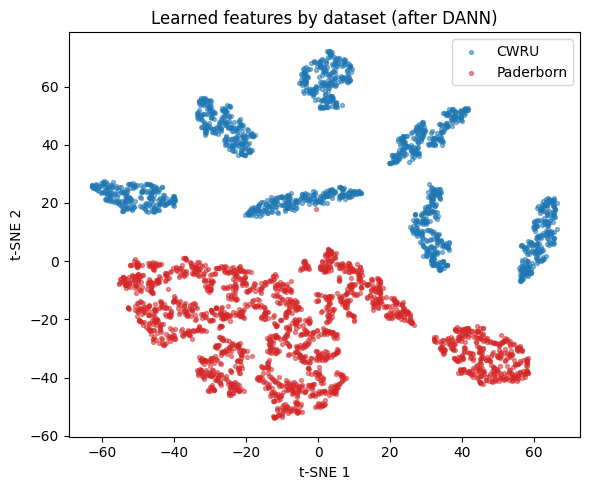

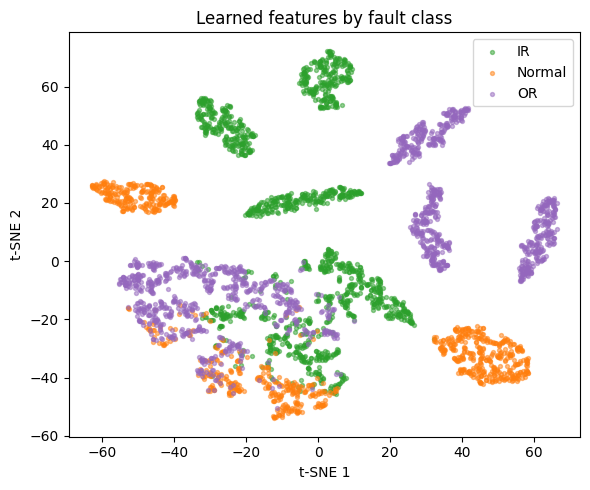

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from tensorflow.keras import Model

# --- extract learned features from the DANN feature extractor ---
feat_model = Model(dann.input, dann.get_layer('features').output)

Fc = feat_model.predict(Xc, verbose=0)   # CWRU features  (n_c, 128)
Fp = feat_model.predict(Xp, verbose=0)   # Paderborn features (n_p, 128)

F_all = np.vstack([Fc, Fp])
domain_all = np.array([0]*len(Fc) + [1]*len(Fp))          # 0=CWRU, 1=PB
label_all  = np.concatenate([yc, yp_bal])                 # fault class 0/1/2

# --- t-SNE to 2D ---
emb = TSNE(n_components=2, perplexity=30, random_state=42,
           init='pca').fit_transform(F_all)

# --- Figure 1: colored by DATASET (the domain-gap story) ---
plt.figure(figsize=(6,5))
for d, name, c in [(0,'CWRU','#1f77b4'), (1,'Paderborn','#d62728')]:
    m = domain_all == d
    plt.scatter(emb[m,0], emb[m,1], s=8, alpha=0.5, label=name, color=c)
plt.legend(); plt.title('Learned features by dataset (after DANN)')
plt.xlabel('t-SNE 1'); plt.ylabel('t-SNE 2'); plt.tight_layout()
plt.savefig('/kaggle/working/tsne_by_dataset.png', dpi=300, bbox_inches='tight')
plt.savefig('/kaggle/working/tsne_by_dataset.pdf', bbox_inches='tight')
plt.show()

# --- Figure 2: colored by FAULT CLASS (do classes align across domains?) ---
plt.figure(figsize=(6,5))
names = ['IR','Normal','OR']
for lab, c in zip([0,1,2], ['#2ca02c','#ff7f0e','#9467bd']):
    m = label_all == lab
    plt.scatter(emb[m,0], emb[m,1], s=8, alpha=0.5, label=names[lab], color=c)
plt.legend(); plt.title('Learned features by fault class')
plt.xlabel('t-SNE 1'); plt.ylabel('t-SNE 2'); plt.tight_layout()
plt.savefig('/kaggle/working/tsne_by_class.png', dpi=300, bbox_inches='tight')
plt.savefig('/kaggle/working/tsne_by_class.pdf', bbox_inches='tight')
plt.show()

In [51]:
import shutil, os
dst = '/kaggle/working/figures'
os.makedirs(dst, exist_ok=True)
for f in os.listdir('/kaggle/working'):
    if f.endswith(('.png', '.pdf')):
        shutil.copy(f'/kaggle/working/{f}', f'{dst}/{f}')
shutil.make_archive('/kaggle/working/all_figures', 'zip', dst)
print("done — download all_figures.zip from the Output panel")

done — download all_figures.zip from the Output panel


In [52]:
import numpy as np, pandas as pd
from scipy.stats import wasserstein_distance
import matplotlib.pyplot as plt

COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']

# --- 1) SHAP importance per feature (CWRU XGBoost model) ---
# Retrain the 9-feature XGBoost on CWRU (3-class) to get clean SHAP importances
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
import shap

le3 = LabelEncoder().fit(['IR','Normal','OR'])
Xc9 = cwru_re[COLS].values
yc9 = le3.transform(cwru_re['fault'])

xgb = XGBClassifier(random_state=42, eval_metric='mlogloss').fit(Xc9, yc9)
expl = shap.TreeExplainer(xgb)
sv = expl.shap_values(Xc9)                      # list or array
sv = np.array(sv)
# mean |SHAP| per feature, averaged over classes & samples
if sv.ndim == 3:      # (classes, samples, features) or (samples, features, classes)
    imp = np.abs(sv).mean(axis=tuple(range(sv.ndim-1))) if sv.shape[-1]==len(COLS) else np.abs(sv).mean(axis=(0,1))
else:
    imp = np.abs(sv).mean(axis=0)
imp = np.asarray(imp).ravel()[:len(COLS)]

# --- 2) Distribution divergence per feature: CWRU vs Paderborn ---
# standardize each dataset per-feature first so divergence isn't just scale
def zt(a): return (a - a.mean(0)) / (a.std(0) + 1e-8)
Cz = zt(cwru_re[COLS].values)
Pz = zt(pb[COLS].values)
div = [wasserstein_distance(Cz[:,i], Pz[:,i]) for i in range(len(COLS))]
div = np.array(div)

# --- 3) Combine and correlate ---
tab = pd.DataFrame({'feature':COLS,
                    'shap_importance':imp/imp.sum(),
                    'domain_divergence':div}).sort_values('shap_importance', ascending=False)
from scipy.stats import pearsonr, spearmanr
r_p, p_p = pearsonr(tab['shap_importance'], tab['domain_divergence'])
r_s, p_s = spearmanr(tab['shap_importance'], tab['domain_divergence'])
print(tab.to_string(index=False))
print(f"\nPearson r = {r_p:.3f} (p={p_p:.3f}) | Spearman r = {r_s:.3f} (p={p_s:.3f})")

# --- 4) Scatter figure ---
plt.figure(figsize=(6,5))
plt.scatter(tab['shap_importance'], tab['domain_divergence'], s=60, color='#d62728')
for _, row in tab.iterrows():
    plt.annotate(row['feature'],
                 (row['shap_importance'], row['domain_divergence']),
                 xytext=(4,4), textcoords='offset points', fontsize=9)
plt.xlabel('SHAP importance (normalized)')
plt.ylabel('CWRU↔Paderborn divergence (Wasserstein)')
plt.title('Do the features the model relies on transfer?')
plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig('/kaggle/working/shap_vs_divergence.png', dpi=300, bbox_inches='tight')
plt.savefig('/kaggle/working/shap_vs_divergence.pdf', bbox_inches='tight')
plt.show()

ValueError: All arrays must be of the same length

In [53]:
print("sv shape:", np.array(sv).shape)
print("imp shape:", np.asarray(imp).shape, "| len(COLS):", len(COLS))
print("div shape:", np.array(div).shape)

sv shape: (1658, 9, 3)
imp shape: (3,) | len(COLS): 9
div shape: (9,)


In [54]:
import numpy as np, pandas as pd
from scipy.stats import wasserstein_distance, pearsonr, spearmanr
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
import shap

COLS = ['max','min','mean','sd','rms','skewness','kurtosis','crest','form']

le3 = LabelEncoder().fit(['IR','Normal','OR'])
Xc9 = cwru_re[COLS].values
yc9 = le3.transform(cwru_re['fault'])

xgb = XGBClassifier(random_state=42, eval_metric='mlogloss').fit(Xc9, yc9)
expl = shap.TreeExplainer(xgb)
sv = expl.shap_values(Xc9)

# --- robust: reduce SHAP output to exactly one importance per feature ---
sv = np.array(sv)
# collapse every axis that ISN'T the length-9 feature axis
abs_sv = np.abs(sv)
# find the axis whose size == number of features
feat_axis = [ax for ax, s in enumerate(abs_sv.shape) if s == len(COLS)]
if not feat_axis:
    raise ValueError(f"No axis of length {len(COLS)} in SHAP shape {abs_sv.shape}")
fax = feat_axis[-1]
# mean over all other axes
other = tuple(ax for ax in range(abs_sv.ndim) if ax != fax)
imp = abs_sv.mean(axis=other)
imp = np.asarray(imp).ravel()
print("imp length:", len(imp))          # must be 9

# --- distribution divergence per feature (standardized) ---
def zt(a): return (a - a.mean(0)) / (a.std(0) + 1e-8)
Cz = zt(cwru_re[COLS].values)
Pz = zt(pb[COLS].values)
div = np.array([wasserstein_distance(Cz[:,i], Pz[:,i]) for i in range(len(COLS))])

assert len(imp) == len(div) == len(COLS), f"lengths: imp={len(imp)}, div={len(div)}, cols={len(COLS)}"

tab = pd.DataFrame({'feature':COLS,
                    'shap_importance':imp/imp.sum(),
                    'domain_divergence':div}).sort_values('shap_importance', ascending=False)
r_p,p_p = pearsonr(tab.shap_importance, tab.domain_divergence)
r_s,p_s = spearmanr(tab.shap_importance, tab.domain_divergence)
print(tab.to_string(index=False))
print(f"\nPearson r={r_p:.3f} (p={p_p:.3f}) | Spearman r={r_s:.3f} (p={p_s:.3f})")

imp length: 9
 feature  shap_importance  domain_divergence
      sd         0.250305           0.166366
     min         0.185847           0.287677
    mean         0.167373           0.226060
     max         0.137058           0.250792
kurtosis         0.114659           0.236327
    form         0.067826           0.828226
skewness         0.036529           0.304064
     rms         0.028944           0.164759
   crest         0.011459           0.099824

Pearson r=-0.124 (p=0.750) | Spearman r=0.200 (p=0.606)


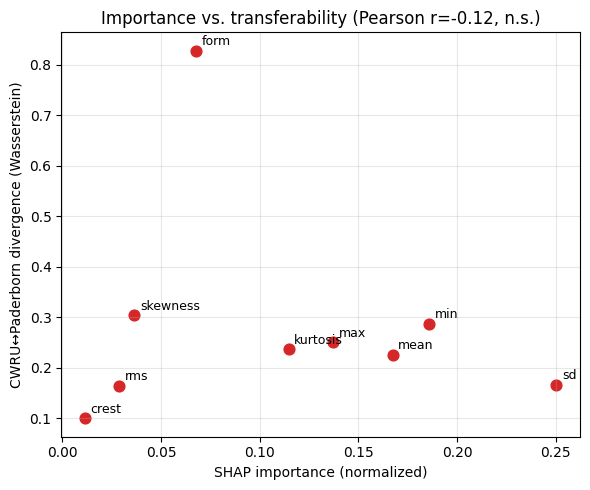

In [55]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
plt.scatter(tab.shap_importance, tab.domain_divergence, s=60, color='#d62728')
for _, r in tab.iterrows():
    plt.annotate(r.feature, (r.shap_importance, r.domain_divergence),
                 xytext=(4,4), textcoords='offset points', fontsize=9)
plt.xlabel('SHAP importance (normalized)')
plt.ylabel('CWRU↔Paderborn divergence (Wasserstein)')
plt.title(f'Importance vs. transferability (Pearson r={r_p:.2f}, n.s.)')
plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig('/kaggle/working/shap_vs_divergence.png', dpi=300, bbox_inches='tight')
plt.savefig('/kaggle/working/shap_vs_divergence.pdf', bbox_inches='tight')
plt.show()

In [56]:
import shutil, os
dst = '/kaggle/working/figures'
os.makedirs(dst, exist_ok=True)
for f in os.listdir('/kaggle/working'):
    if f.endswith(('.png', '.pdf')):
        shutil.copy(f'/kaggle/working/{f}', f'{dst}/{f}')
shutil.make_archive('/kaggle/working/all_figures', 'zip', dst)
print("done — download all_figures.zip from the Output panel")

done — download all_figures.zip from the Output panel
